Name: Sana Raza

Labpartner(s)

In [1]:
#import statements go here
import matplotlib.pyplot as plt

# Class 8.1

Today we are presenting movies! The homework is to work on your proposals. 


**W.1** This week our warmups are focused on applying your Pandas skills. Please download the 2026 World Cup player stats from slack (pinned to #announcements), and do some analyisis on this, whatever you are keen on. We'll do more with this on Wednesday. Show your work and make sure you write some text about what you found. 

In [2]:
import pandas as pd

# Load the CSV file into a DataFrame
df = pd.read_csv('player_stats.csv')

# View the first 5 rows
print(df.head())

   player_id            player_name  team_id position  matches_played  \
0          1       José Raúl Rangel        1       GK               5   
1          2  Jorge Eduardo Sanchez        1      DEF               5   
2          3     César Jasib Montes        1      DEF               3   
3          4     Edson Omar Alvarez        1      DEF               2   
4          5   Johan Felipe Vasquez        1      DEF               2   

   matches_started  minutes_played  goals  assists  shots  ...  yellow_cards  \
0                5             438      0        0    NaN  ...             0   
1                5             439      0        1    NaN  ...             0   
2                2             165      0        0    NaN  ...             0   
3                0              75      0        0    NaN  ...             1   
4                2             180      0        0    NaN  ...             0   

   red_cards  penalty_goals  own_goals  clean_sheets  saves  goals_conceded  \
0

In [3]:
# Counting how many values are missing in each column

df.isna().sum()

player_id             0
player_name           0
team_id               0
position              0
matches_played        0
matches_started       0
minutes_played        0
goals                 0
assists               0
shots              1248
shots_on_target    1248
yellow_cards          0
red_cards             0
penalty_goals         0
own_goals             0
clean_sheets       1103
saves              1103
goals_conceded     1103
average_rating     1248
data_source         209
last_verified         0
dtype: int64

The columns shots, shots_on_target and average_rating are completely empty, so I will remove them.
penalty_goals is 0 for every player, which can't be true for a World Cup, so I remove it too. saves, clean_sheets and goals_conceded are only filled in for goalkeepers. 209 players never played a minute, so I make a separate table with only players who played.

In [4]:
df = df.drop(columns=['shots', 'shots_on_target', 'average_rating', 'penalty_goals'])

played = df[df['minutes_played'] > 0].copy()
print(len(played), 'players actually played')

1039 players actually played


In [5]:
# The following will show who are the top 10 goal scorers.
played.sort_values('goals', ascending=False)[['player_name', 'team_id', 'position', 'goals', 'assists']].head(10)

,player_name,team_id,position,goals,assists
841,Kylian Mbappe,33,FWD,10,4
945,Lionel Andrés Messi,37,FWD,8,4
918,Erling Braut Haaland,36,FWD,7,0
1153,Jude Victor William Bellingham,45,MID,7,1
1152,Harry Edward Kane,45,FWD,6,1
748,Mikel Oyarzabal,29,FWD,5,1
838,Masour Ousmane Dembele,33,FWD,5,2
875,Ismaila Sarr,34,FWD,4,1
843,Bradley Jean-Manuel Essolisa Barcola,33,FWD,4,1
15,Julián Andrés Quinones,1,FWD,4,1


In [6]:
# The following are the top players by goals + assists per 90 minutes. I am counting only players with at least 270 minutes.

played['goals_assists'] = played['goals'] + played['assists']
played['per_90'] = played['goals_assists'] / played['minutes_played'] * 90

regulars = played[played['minutes_played'] >= 270]
regulars.sort_values('per_90', ascending=False)[['player_name', 'team_id', 'minutes_played', 'goals_assists', 'per_90']].head(10)

,player_name,team_id,minutes_played,goals_assists,per_90
945,Lionel Andrés Messi,37,590,12,1.830508
841,Kylian Mbappe,33,711,14,1.772152
838,Masour Ousmane Dembele,33,363,7,1.735537
843,Bradley Jean-Manuel Essolisa Barcola,33,283,5,1.590106
1150,Bukayo Ayoyinka Saka,45,373,6,1.447721
918,Erling Braut Haaland,36,450,7,1.400000
748,Mikel Oyarzabal,29,394,6,1.370558
968,Riyad Karim Mahrez,38,282,4,1.276596
875,Ismaila Sarr,34,366,5,1.229508
1153,Jude Victor William Bellingham,45,596,8,1.208054


position
DEF     29
FWD    172
GK       0
MID     93
Name: goals, dtype: int64


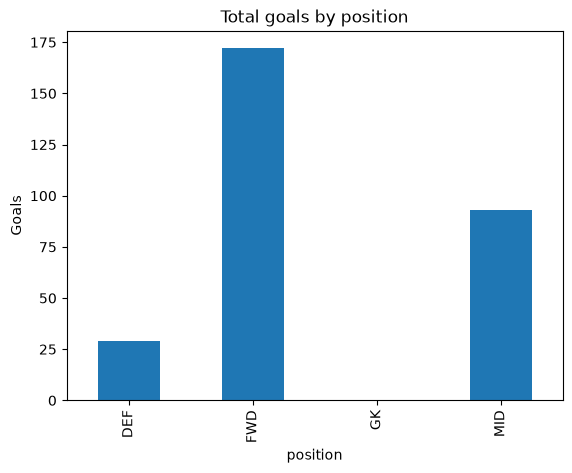

In [7]:
# The following shows  how many goals each position scored, with a bar chart.

goals_by_position = played.groupby('position')['goals'].sum()
print(goals_by_position)

goals_by_position.plot(kind='bar')
plt.title('Total goals by position')
plt.ylabel('Goals')
plt.show()

games
3    0.62500
4    1.37500
5    1.50000
6    1.87500
8    2.21875
Name: goals_per_game, dtype: float64
Correlation: 0.6513405278687755


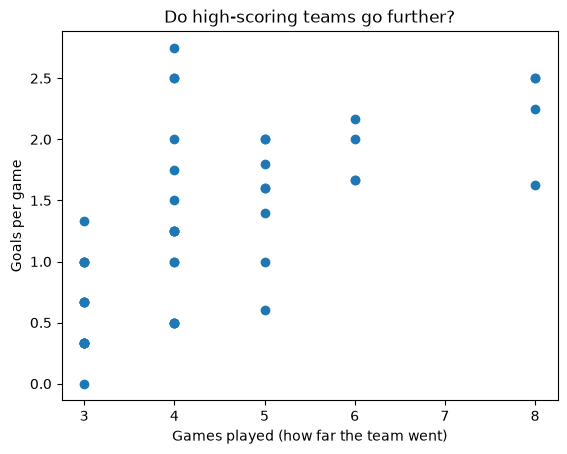

In [8]:
# This checks whether teams that scored more went further. The most games any player on a team played equals how many games that team played: 3 means out in the groups, and 8 means semifinalist.

games = df.groupby('team_id')['matches_played'].max()
goals = df.groupby('team_id')['goals'].sum()

teams = pd.DataFrame({'games': games, 'goals': goals})
teams['goals_per_game'] = teams['goals'] / teams['games']

print(teams.groupby('games')['goals_per_game'].mean())
print('Correlation:', teams['games'].corr(teams['goals_per_game']))

plt.scatter(teams['games'], teams['goals_per_game'])
plt.xlabel('Games played (how far the team went)')
plt.ylabel('Goals per game')
plt.title('Do high-scoring teams go further?')
plt.show()

In [9]:
# These are the best goalkeepers by save percentage, counting only keepers with at least 270 minutes.

gk = played[(played['position'] == 'GK') & (played['minutes_played'] >= 270)].copy()
gk['save_pct'] = gk['saves'] / (gk['saves'] + gk['goals_conceded']) * 100

gk.sort_values('save_pct', ascending=False)[['player_name', 'team_id', 'saves', 'goals_conceded', 'clean_sheets', 'save_pct']].head(10)

,player_name,team_id,saves,goals_conceded,clean_sheets,save_pct
750,Unai Simon,29,13.0,0.0,5.0,100.000000
728,David Raya,29,8.0,1.0,2.0,88.888889
1040,Diogo Diogo Costa,41,22.0,3.0,2.0,88.000000
494,Hernán Ismael Galindez,20,25.0,4.0,1.0,86.206897
1129,Camilo Andres Vargas,44,6.0,1.0,3.0,85.714286
676,Ali Reza Beiranvand,27,16.0,3.0,1.0,84.210526
335,Matthew Andrew Geary Freese,13,5.0,1.0,2.0,83.333333
349,Orlando Daniel Gill,14,29.0,6.0,2.0,82.857143
754,José Vozinha,30,23.0,5.0,2.0,82.142857
26,Ronwen Hayden Williams,2,17.0,4.0,1.0,80.952381


         team_goals  top_scorer_goals  star_share
team_id                                          
42                5                 3   60.000000
36               12                 7   58.333333
33               20                10   50.000000
37               18                 8   44.444444
41                7                 3   42.857143
1                10                 4   40.000000
9                10                 4   40.000000
34               10                 4   40.000000
19                5                 2   40.000000
38                5                 2   40.000000
Average share for all teams: 36.6


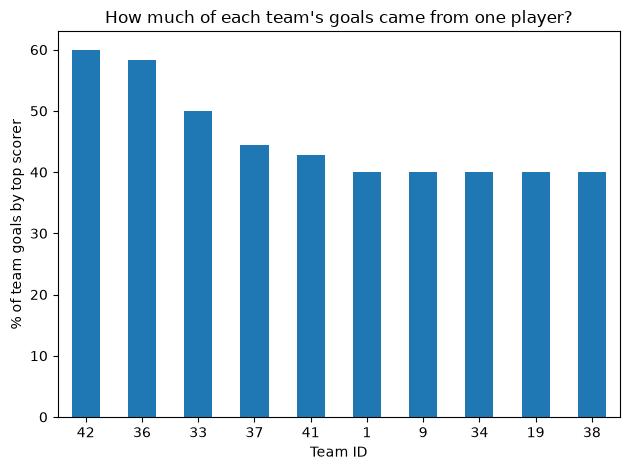

In [10]:
# Finding out which teams dependend on one star player?

team_goals = played.groupby('team_id')['goals'].sum()
top_scorer_goals = played.groupby('team_id')['goals'].max()

teams = pd.DataFrame({'team_goals': team_goals, 'top_scorer_goals': top_scorer_goals})
teams = teams[teams['team_goals'] >= 5]
teams['star_share'] = teams['top_scorer_goals'] / teams['team_goals'] * 100

# if two teams have the same share, the team with more goals goes first
top10 = teams.sort_values(['star_share', 'team_goals'], ascending=False).head(10)
print(top10)
print('Average share for all teams:', round(teams['star_share'].mean(), 1))

top10['star_share'].plot(kind='bar')
plt.title("How much of each team's goals came from one player?")
plt.xlabel('Team ID')
plt.ylabel('% of team goals by top scorer')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

On average, a team's top scorer got about 37% of the team's goals (teams with 5+ goals only).
Team 42 relied the most on one player (60%), but it only scored 5 goals, so that's 3 goals from one player.
Team 36 is a better example of a one-star team: a player scored 7 of its 12 goals (58%).


## What I found

1. There are 1,248 players from 48 teams, but 209 of them never played a minute.
Some columns could not be used: shots, shots_on_target and average_rating are completely empty,
and penalty_goals is 0 for everyone. There are no team names, only team numbers.

2. When I compare players by goals + assists per 90 minutes (only players with 270+ minutes),
Messi comes first (1.83), just ahead of Mbappe (1.77). Three of the top four players are from team 33,
so that team had a very strong attack.

3. Forwards scored 172 goals, midfielders 93, defenders 29 and goalkeepers 0.
So forwards scored more than half of all the goals, which is what I expected.

4. Teams that scored more went further. Teams that went out in the
group stage scored about 0.6 goals per game, while the 4 semifinalists scored about 2.2 goals per game.
The correlation is 0.65, which is a fairly strong positive relationship.

# Lecture 8.1

### Agenda:

- Questions
- Show us your movies

### Questions

# Lab 8.1

**E.0** Complete the previous labs if you are behind.

**E.1** Sign up for an LSU HPC account:

Each student should submit an HPC account request through the LSU HPC account request portal https://accounts.hpc.lsu.edu/login_request.php. In the Account Sponsor field, use my name and email address as your sponsor. 

We will be going over how to use the LSU HPC in the coming weeks. 


**E.2** Create an outline for your research proposal. Review the proposal rubric and create an outline for how you will meet all the grading criteria. Turn this in on Moodle, due by this Sunday.

**E.3** (Optional) Explore methods related to your final project, for example by exploring tutorials on datacamp or other resources.

Methods that I plan to use:

1. Linear regression
2. Non-linear power law
3. Log-log linear fit as a simple non-linear check.
4. Model comparison: AIC (or a likelihood-ratio test where the models are nested), plus R².

**E.4** Make notes for yourself on progamming tecniques and commands you learned in the this week, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv('player_stats.csv')

# set_index(): use a column as the row labels instead of 0, 1, 2...
players = data.set_index('player_name')


In [13]:
# An index can have two levels: position first, then team
multi = data.set_index(['position', 'team_id'])

# Pick one value of the outer level
print(multi.loc['GK'].head())

# Pick specific (outer, inner) pairs with tuples
print(multi.loc[[('FWD', 33), ('FWD', 37)], ['player_name', 'goals']])

# sort_index(): sort by the index values
print(multi.sort_index().head())

# Sort each level in a different direction
print(multi.sort_index(level=['position', 'team_id'], ascending=[True, False]).head())

         player_id                player_name  matches_played  \
team_id                                                         
1                1           José Raúl Rangel               5   
1               12             Carlos Acevedo               0   
1               13  Francisco Guillermo Ochoa               1   
2               27     Ronwen Hayden Williams               4   
2               42        Sipho Justin Chaine               0   

         matches_started  minutes_played  goals  assists  shots  \
team_id                                                           
1                      5             438      0        0    NaN   
1                      0               0      0        0    NaN   
1                      0              12      0        0    NaN   
2                      4             360      0        0    NaN   
2                      0               0      0        0    NaN   

         shots_on_target  yellow_cards  red_cards  penalty_goals  own_goal

In [14]:
# The index must be sorted before slicing with .loc
srt = multi.sort_index()

# Slice outer level: everything from DEF to FWD (with .loc the end IS included)
print(srt.loc['DEF':'FWD'].shape)

# Slice inner level using tuples, and slice columns at the same time
print(srt.loc[('FWD', 30):('FWD', 33), 'player_name':'goals'].head())

# .iloc[] picks by row/column NUMBER (like a list; the end is NOT included)
print(data.iloc[0:5, 1:4])      # rows 0-4, columns 1-3
print(data.iloc[:, -1].head())  # every row, last column

(734, 19)
                               player_name  matches_played  matches_started  \
position team_id                                                              
FWD      30         BENCHIMOLGilson Gilson               2                1   
         30       Dailon Dailon Livramento               3                2   
         30                     Isaac Ryan               4                4   
         31              Yahya Aiman Yahya               0                0   
         31                    Tariq Feras               3                3   

                  minutes_played  goals  
position team_id                         
FWD      30                   78      0  
         30                  175      0  
         30                  331      0  
         31                    0      0  
         31                  240      0  
             player_name  team_id position
0       José Raúl Rangel        1       GK
1  Jorge Eduardo Sanchez        1      DEF
2     César J

In [15]:
# Small made-up match table to show date slicing
matches = pd.DataFrame({
    'date': ['2026-06-11', '2026-06-20', '2026-07-01', '2026-07-10', '2026-07-19'],
    'stage': ['Group', 'Group', 'Round of 32', 'Quarterfinal', 'Final'],
    'goals': [3, 1, 2, 4, 2],
})
matches['date'] = pd.to_datetime(matches['date'])   # turn text into real dates
matches = matches.set_index('date').sort_index()

print(matches.loc['2026-06'])                   # all of June 2026
print(matches.loc['2026-06-15':'2026-07-05'])   # between two dates

            stage  goals
date                    
2026-06-11  Group      3
2026-06-20  Group      1
                  stage  goals
date                          
2026-06-20        Group      1
2026-07-01  Round of 32      2


In [16]:
# pivot_table(): a summary table, like groupby but with rows AND columns
pt = data.pivot_table(values='goals', index='team_id', columns='position',
                      aggfunc='sum', fill_value=0)   # fill_value=0 replaces empty cells
print(pt.head())

# Pivot tables are DataFrames, so .loc works on them too
print(pt.loc[33:37])

# Calculating on a pivot table
print(pt.mean(axis='index'))           # average of each column (per position)
print(pt.mean(axis='columns').head())  # average of each row (per team)

# Several summary functions at once
print(data.pivot_table(values='goals', index='position', aggfunc=['sum', 'mean']))

position  DEF  FWD  GK  MID
team_id                    
1           1    7   0    2
2           0    1   0    1
3           0    1   0    1
4           1    0   0    1
5           0    6   0    2
position  DEF  FWD  GK  MID
team_id                    
33          0   20   0    0
34          0    6   0    4
35          0    1   0    0
36          2    8   0    2
37          2   13   0    3
position
DEF    0.604167
FWD    3.583333
GK     0.000000
MID    1.937500
dtype: float64
team_id
1    2.5
2    0.5
3    0.5
4    0.5
5    2.0
dtype: float64
           sum      mean
         goals     goals
position                
DEF         29  0.068884
FWD        172  0.549521
GK           0  0.000000
MID         93  0.252033


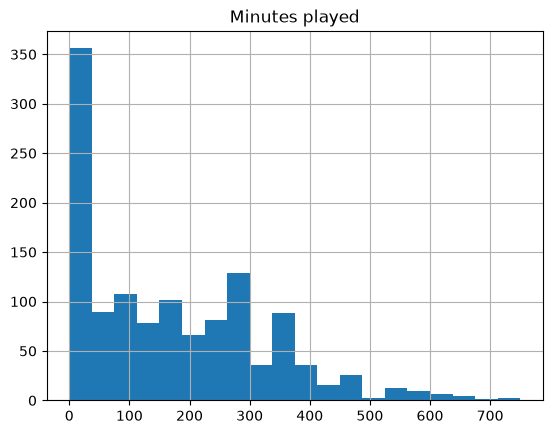

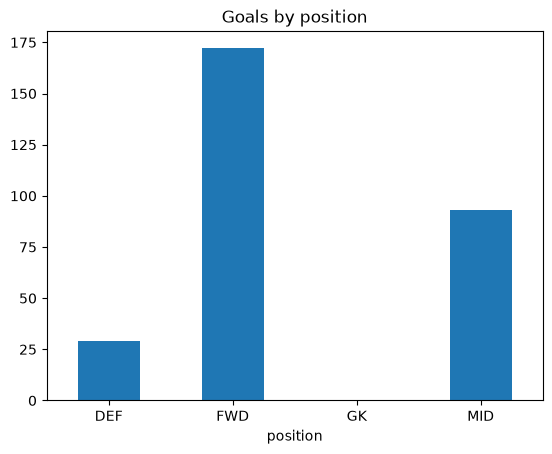

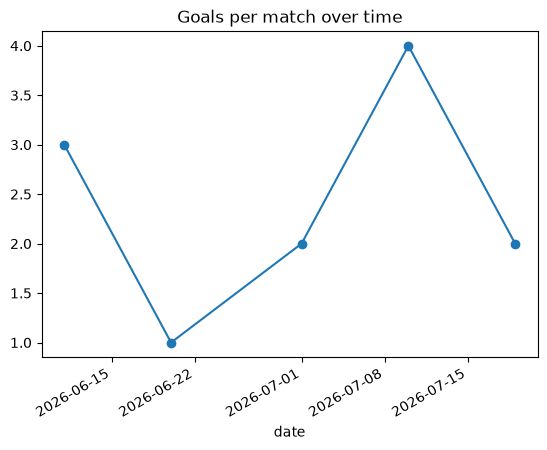

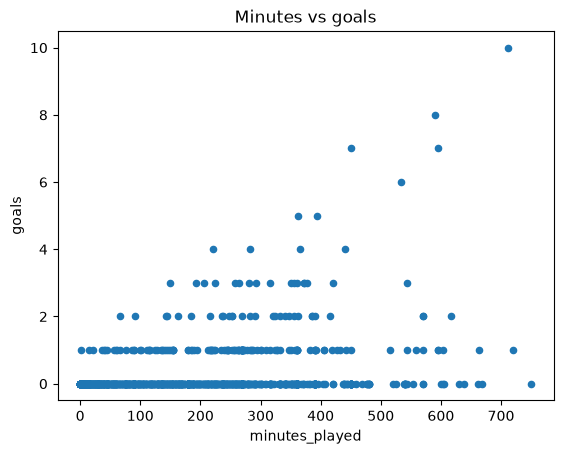

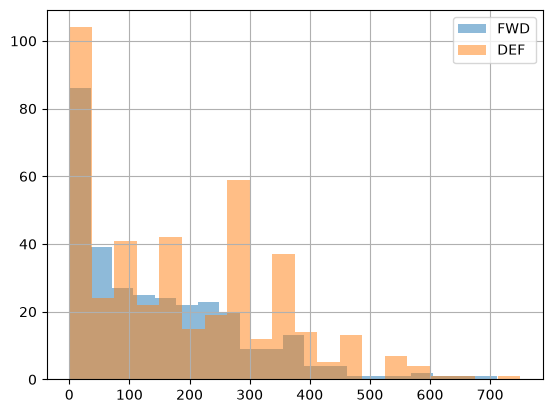

In [17]:
# Histogram: how values are spread out
data['minutes_played'].hist(bins=20)
plt.title('Minutes played')
plt.show()

# Bar chart: compare groups
data.groupby('position')['goals'].sum().plot(kind='bar', rot=0)
plt.title('Goals by position')
plt.show()

# Line chart: change over time
matches['goals'].plot(kind='line', marker='o')
plt.title('Goals per match over time')
plt.show()

# Scatter plot: relationship between two columns
data.plot(x='minutes_played', y='goals', kind='scatter')
plt.title('Minutes vs goals')
plt.show()

# Two histograms on top of each other (alpha = see-through)
data[data['position'] == 'FWD']['minutes_played'].hist(alpha=0.5, bins=20)
data[data['position'] == 'DEF']['minutes_played'].hist(alpha=0.5, bins=20)
plt.legend(['FWD', 'DEF'])
plt.show()